# 04 · A/B test of the retention campaign — design and **simulation**

> ⚠️ **SIMULATION.** The dataset contains no experiment. Everything below
> that looks like "results" is generated from *assumed* churn rates. The goal
> is to show the design, the analysis and the pitfalls before a real launch.
> The only real input is the baseline churn rate of the targeted segment,
> which comes from the model's predictions on the hold-out set.

## 1. Experiment design

| Item | Choice |
|---|---|
| Unit of randomisation | customer (individual-level random split 50/50) |
| Population | customers the model selects for the campaign (`E[profit] > 0`) |
| Treatment | retention contact + offer |
| Control | no contact (business as usual) |
| Primary metric | churn rate within 90 days after assignment |
| Hypotheses | H0: p_T = p_C; H1: p_T ≠ p_C (two-sided, α = 5%) |
| Guardrails | offer cost per retained customer, complaints / opt-outs, revenue per customer |
| Duration | fixed in advance; analysed once at the end (no peeking) |

Why randomise *inside* the targeted segment: we want the causal effect of
the contact on the people we would actually contact. Comparing contacted
customers with everyone else would mix the treatment effect with the fact
that targeted customers are riskier by construction (selection bias).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.config import load_config, path, set_seed
from src import ab_testing as AB
from src.plots import ACCENT, GOOD, MUTED, NEUTRAL, RISK, save, save_table, setup_style

cfg = load_config()
SEED = set_seed()
setup_style()
ab = cfg["ab_test"]
rng = np.random.default_rng(SEED)
alpha, power = ab["alpha"], ab["power"]

test = pd.read_csv(path("processed") / "test_with_business.csv")
targeted = test[test.target == 1]
# Baseline = expected churn in the targeted segment without treatment.
# We use the mean calibrated probability (what we'd know before launch).
p_control = float(targeted["proba"].mean()) if len(targeted) else ab["baseline_churn_rate_fallback"]
print(f"Targeted segment on hold-out: {len(targeted)} customers, "
      f"mean predicted churn = {p_control:.1%} (observed: {targeted.churned.mean():.1%})")

Targeted segment on hold-out: 293 customers, mean predicted churn = 91.0% (observed: 91.8%)


## 2. MDE and power analysis

**MDE (minimum detectable effect)** — the smallest effect the business would
act on. If contact saves a share *s* of would-be churners, treatment churn is
p_C × (1 − s), so the relative churn reduction equals *s*. Notebook 03 shows
the campaign breaks even at s ≈ 11% (`business_robustness.csv`). We set the
MDE at **15%** — comfortably above break-even, so a "significant" result
also means "profitable"; detecting effects closer to 11% would need roughly
2× the sample (n ∝ 1/MDE²). Power 80%: if the true effect is ≥ MDE, the
test detects it 4 times out of 5.

In [2]:
mde = ab["mde_relative"]
n_sm = AB.sample_size_per_arm(p_control, mde, alpha, power)
n_formula = AB.sample_size_formula(p_control, mde, alpha, power)
print(f"p_control = {p_control:.3f}, p_treatment at MDE = {p_control * (1 - mde):.3f}")
print(f"Sample size per arm: statsmodels (Cohen's h) = {n_sm:,} | textbook formula = {n_formula:,}")
print(f"Total customers needed: {2 * n_sm:,}")

mdes = [0.05, 0.075, 0.10, 0.15, 0.20, 0.25, 0.30]
ptab = AB.power_table(p_control, mdes, alpha, power)
save_table(ptab, "ab_power_table")
ptab

p_control = 0.910, p_treatment at MDE = 0.774
Sample size per arm: statsmodels (Cohen's h) = 108 | textbook formula = 111
Total customers needed: 216


,mde_relative,p_control,p_treatment,n_per_arm
0,0.050,0.910206,0.864695,750
1,0.075,0.910206,0.841940,360
2,0.100,0.910206,0.819185,216
3,0.150,0.910206,0.773675,108
4,0.200,0.910206,0.728165,66
5,0.250,0.910206,0.682654,46
6,0.300,0.910206,0.637144,34


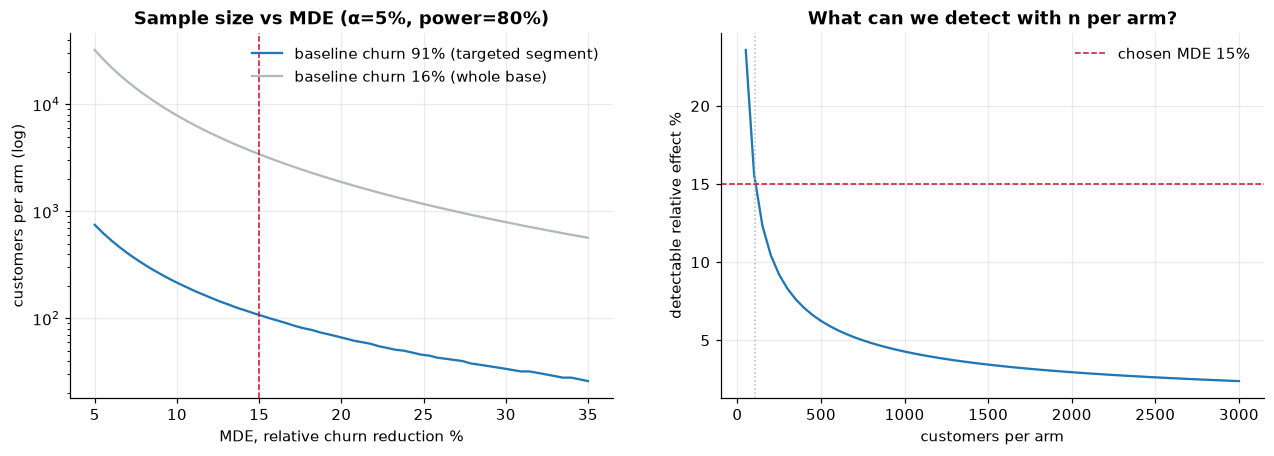

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
grid_mde = np.linspace(0.05, 0.35, 60)
for pc, c in [(p_control, ACCENT), (0.16, MUTED)]:
    axes[0].plot(grid_mde * 100, [AB.sample_size_per_arm(pc, m, alpha, power) for m in grid_mde],
                 color=c, label=f"baseline churn {pc:.0%}" + (" (targeted segment)" if pc == p_control else " (whole base)"))
axes[0].axvline(mde * 100, color=RISK, ls="--", lw=1)
axes[0].set_yscale("log")
axes[0].set(xlabel="MDE, relative churn reduction %", ylabel="customers per arm (log)",
            title="Sample size vs MDE (α=5%, power=80%)")
axes[0].legend()

ns = np.arange(50, 3001, 50)
axes[1].plot(ns, [AB.mde_for_sample(p_control, n, alpha, power) * 100 for n in ns], color=ACCENT)
axes[1].axhline(mde * 100, color=RISK, ls="--", lw=1, label=f"chosen MDE {mde:.0%}")
axes[1].axvline(n_sm, color=MUTED, ls=":", lw=1)
axes[1].set(xlabel="customers per arm", ylabel="detectable relative effect %",
            title="What can we detect with n per arm?")
axes[1].legend()
save(fig, "ab_power_analysis")
plt.show()

Targeting the high-risk segment is also good for the *experiment*: with a
baseline of ~91% instead of 16%, the same relative effect is a much bigger
absolute difference, so far fewer customers are needed (compare the two
curves on the left).

**Feasibility.** ~110 customers per arm (~220 in total) is fewer than the
293 customers the campaign targets in the hold-out alone, so the pilot fits
in a single campaign wave. Caveat: holding out a control group means *not*
contacting ~110 high-risk customers — that is the price of learning the true
effect, and it is why the control group should be no larger than needed.

**Small-sample caveat.** With 91% churn, the control arm expects only ~10
customers who stay. The normal approximation behind the z-test is
borderline at that count, so below we also report **Fisher's exact test**
as a check.

## 3. One simulated experiment (true effect = 20% relative reduction)

In [4]:
true_eff = ab["simulated_true_effect_relative"]
p_treat = p_control * (1 - true_eff)
control, treatment = AB.simulate_experiment(p_control, p_treat, n_sm, rng)
z_res = AB.analyse_ztest(control, treatment, alpha)
b_res = AB.bootstrap_diff(control, treatment, ab["n_bootstrap"], rng, alpha)

from scipy.stats import fisher_exact
_, p_fisher = fisher_exact([[treatment.sum(), len(treatment) - treatment.sum()],
                            [control.sum(), len(control) - control.sum()]])
print(f"Fisher exact test p-value: {p_fisher:.2e}")
res = pd.DataFrame({
    "z-test": [z_res["abs_diff"], z_res["ci_low"], z_res["ci_high"], z_res["p_value"]],
    "bootstrap": [z_res["abs_diff"], b_res["ci_low"], b_res["ci_high"], b_res["p_value"]],
}, index=["diff (T − C)", "95% CI low", "95% CI high", "p-value"])
print(f"[SIMULATED] control churn {z_res['p_control']:.1%}, treatment churn {z_res['p_treatment']:.1%}, "
      f"relative change {z_res['rel_diff']:+.1%}")
res.round(4)

Fisher exact test p-value: 2.82e-05
[SIMULATED] control churn 94.4%, treatment churn 73.1%, relative change -22.5%


,z-test,bootstrap
diff (T − C),-0.2130,-0.2130
95% CI low,-0.3071,-0.3056
95% CI high,-0.1189,-0.1204
p-value,0.0000,0.0000


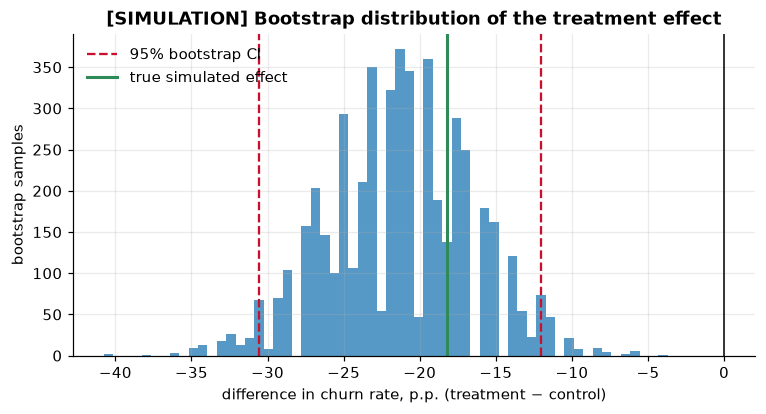

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(b_res["diffs"] * 100, bins=60, color=ACCENT, alpha=0.75)
ax.axvline(0, color="black", lw=1)
ax.axvline(b_res["ci_low"] * 100, color=RISK, ls="--")
ax.axvline(b_res["ci_high"] * 100, color=RISK, ls="--", label="95% bootstrap CI")
ax.axvline(-(p_control - p_treat) * 100, color=GOOD, lw=2, label="true simulated effect")
ax.set(xlabel="difference in churn rate, p.p. (treatment − control)", ylabel="bootstrap samples",
       title="[SIMULATION] Bootstrap distribution of the treatment effect")
ax.legend()
save(fig, "ab_bootstrap")
plt.show()

The z-test and the bootstrap agree (as they should for proportions with
n in the hundreds — the normal approximation is fine). The bootstrap is
shown because it generalises to metrics with no closed-form SE (e.g.
revenue per customer, median balance, ratio metrics).

**Business translation of the CI:** the campaign reduces 90-day churn in
the targeted segment by between |CI high| and |CI low| p.p.; with
~N targeted customers per month that is the range of customers saved.

## 4. Does the design work? Monte-Carlo check of power and false positives

In [6]:
n_sims = ab["n_simulations"]
emp_power = AB.monte_carlo_power(p_control, p_control * (1 - mde), n_sm, n_sims, rng, alpha)
emp_power_true = AB.monte_carlo_power(p_control, p_treat, n_sm, n_sims, rng, alpha)
emp_fpr = AB.monte_carlo_power(p_control, p_control, n_sm, n_sims, rng, alpha)
mc = pd.DataFrame({
    "scenario": [f"true effect = MDE ({mde:.0%})", f"true effect = {true_eff:.0%}", "A/A test (no effect)"],
    "rejection rate": [emp_power, emp_power_true, emp_fpr],
    "should be": [f"≈ {power:.0%} (power)", f"> {power:.0%}", f"≈ {alpha:.0%} (α)"],
})
save_table(mc, "ab_monte_carlo")
mc

,scenario,rejection rate,should be
0,true effect = MDE (15%),0.798,≈ 80% (power)
1,true effect = 20%,0.945,> 80%
2,A/A test (no effect),0.054,≈ 5% (α)


## 5. The peeking problem
A manager checks the dashboard every few days and stops the test as soon as
p < 0.05. Below, **there is no true effect** (A/A), the test is checked at
20 interim points, and we count how often it *ever* crosses p < 0.05.

In [7]:
looks = ab["peeking_checks"]
n_peek = ab["peeking_simulations"]  # more runs: the boundary is a 5% tail quantile
pv_null = AB.simulate_peeking(p_control, p_control, n_sm, looks, n_peek, rng)
pv_alt = AB.simulate_peeking(p_control, p_treat, n_sm, looks, n_peek, rng)
err = AB.peeking_error_rates(pv_null, alpha)
pocock = AB.calibrate_pocock_alpha(pv_null, alpha)

# validate the boundary on FRESH null simulations (not the ones used to calibrate it)
pv_null_fresh = AB.simulate_peeking(p_control, p_control, n_sm, looks, n_peek, rng)
fpr_pocock = float((pv_null_fresh < pocock).any(axis=1).mean())
power_fixed = float((pv_alt[:, -1] < alpha).mean())
power_pocock = float((pv_alt < pocock).any(axis=1).mean())
stop_look = np.where((pv_alt < pocock).any(axis=1), (pv_alt < pocock).argmax(axis=1) + 1, looks)

peek = pd.DataFrame({
    "strategy": ["Fixed horizon (look once at the end)",
                 f"Naive peeking ({looks} looks, stop at first p<{alpha})",
                 f"Pocock-style boundary ({looks} looks, p<{pocock:.4f} each)"],
    "false positive rate (A/A)": [err["fixed_horizon_reject_rate"], err["peeking_reject_rate"], fpr_pocock],
    "power (true effect)": [power_fixed, float((pv_alt < alpha).any(axis=1).mean()), power_pocock],
})
save_table(peek, "ab_peeking")
peek.round(3)

,strategy,false positive rate (A/A),power (true effect)
0,Fixed horizon (look once at the end),0.052,0.935
1,"Naive peeking (10 looks, stop at first p<0.05)",0.169,0.959
2,"Pocock-style boundary (10 looks, p<0.0157 each)",0.047,0.888


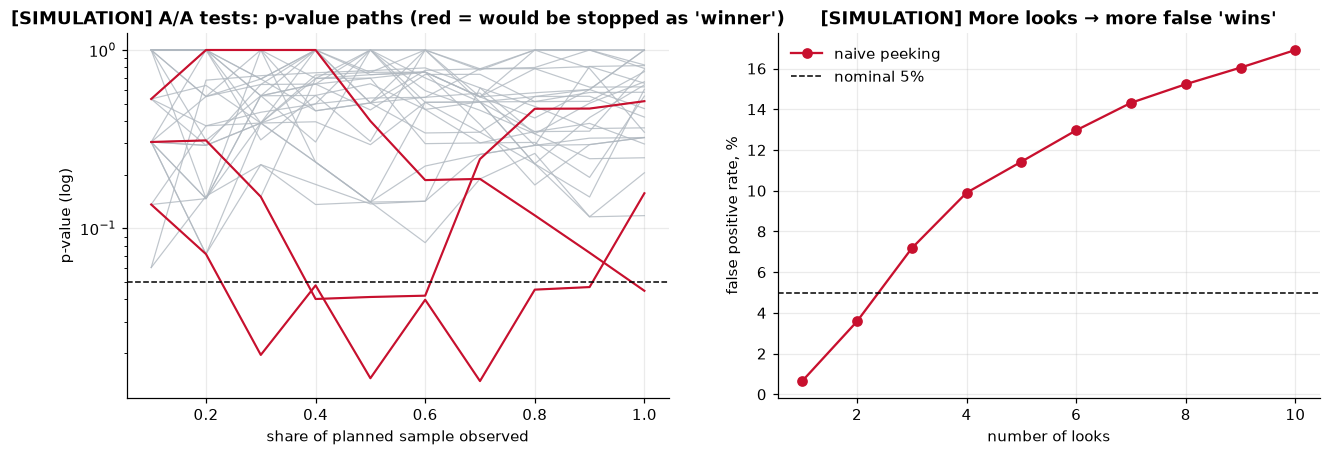

Pocock boundary: average stopping look under true effect = 5.5 of 10


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
frac = np.arange(1, looks + 1) / looks
for i in range(30):
    axes[0].plot(frac, pv_null[i], color=MUTED, lw=0.8, alpha=0.8)
crossed = np.where((pv_null[:30] < alpha).any(axis=1))[0]
for i in crossed[:5]:
    axes[0].plot(frac, pv_null[i], color=RISK, lw=1.4)
axes[0].axhline(alpha, color="black", ls="--", lw=1)
axes[0].set_yscale("log")
axes[0].set(xlabel="share of planned sample observed", ylabel="p-value (log)",
            title="[SIMULATION] A/A tests: p-value paths (red = would be stopped as 'winner')")
cum_fpr = [(pv_null[:, :k] < alpha).any(axis=1).mean() for k in range(1, looks + 1)]
axes[1].plot(range(1, looks + 1), np.array(cum_fpr) * 100, marker="o", color=RISK, label="naive peeking")
axes[1].axhline(alpha * 100, color="black", ls="--", lw=1, label="nominal 5%")
axes[1].set(xlabel="number of looks", ylabel="false positive rate, %",
            title="[SIMULATION] More looks → more false 'wins'")
axes[1].legend()
save(fig, "ab_peeking")
plt.show()
print(f"Pocock boundary: average stopping look under true effect = {stop_look.mean():.1f} of {looks}")

**What the simulation shows** (exact numbers in the table above)
* Looking once at the end keeps the false positive rate near 5% as designed.
* Stopping at the first p < 0.05 inflates false positives several-fold:
  under H0 the p-value wanders, and if you look often enough it dips below
  0.05 at some point. More looks → worse (right chart).
* The early looks here are tiny (~11 customers per arm), where the z-test is
  crude. That makes the exact inflation specific to this design, but the
  direction is universal.
* Fixes: (1) fix the sample size in advance and look once; (2) if early
  stopping is needed, use a **group-sequential design** (Pocock /
  O'Brien-Fleming alpha-spending) — here a Pocock-style constant boundary
  calibrated by simulation restores ~5%, at the cost of some power; (3)
  always-valid / Bayesian sequential methods.

## 6. After the test: how results feed back into the business case
* The measured relative churn reduction × baseline replaces the assumed
  `retention_success_rate` in `config.yaml`; rerun notebook 03.
* With treatment/control data per customer, we can train an **uplift
  model** (T-learner / X-learner) to target *persuadable* customers rather
  than merely high-risk ones — the natural next iteration of this project.

> Reminder: **all numbers in this notebook are simulated** from the
> assumptions in `config.yaml → ab_test`.